# Chapter 11 — ML 기반 이상 탐지 (실습)

## 실습 목표
1. BENIGN 만으로 K-Means / DBSCAN / Isolation Forest 학습
2. 전체에 예측 적용
3. ROC-AUC, P/R 비교
4. contamination 튜닝

In [ ]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [1]:
# === 한글 폰트 설정 (matplotlib) ===
from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

In [2]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q pandas
# !pip install -q numpy
# !pip install -q matplotlib
# !pip install -q scikit-learn

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
rng = np.random.default_rng(42)

In [4]:
# 데이터 — ch09 형식
def make_rows(n, label, dur, pkts, syn):
    return pd.DataFrame({
        'Flow Duration': rng.uniform(*dur, size=n),
        'Total Fwd Packets': rng.integers(*pkts, size=n),
        'SYN Flag Count': rng.uniform(*syn, size=n),
        'Label': label,
    })
df = pd.concat([
    make_rows(16000, 'BENIGN',   (1000, 1_000_000), (5, 100),    (0, 0.05)),
    make_rows( 2300, 'DDoS',     (10, 5000),         (500, 5000), (0.4, 0.7)),
    make_rows( 1200, 'PortScan', (1, 200),           (1, 5),      (0.85, 1.0)),
], ignore_index=True).sample(frac=1, random_state=0).reset_index(drop=True)
df['log_dur'] = np.log1p(df['Flow Duration'])
df['log_pkts'] = np.log1p(df['Total Fwd Packets'])
FEATURES = ['log_dur', 'log_pkts', 'SYN Flag Count']
y = (df['Label'] != 'BENIGN').astype(int)

scaler = RobustScaler()
from sklearn.model_selection import train_test_split
train, held_out = train_test_split(df, test_size=0.3, stratify=y, random_state=42)
fit_train, validation = train_test_split(train, test_size=0.2, stratify=train['Label'], random_state=43)
normal_train = fit_train[fit_train['Label']=='BENIGN']
normal_valid = validation[validation['Label']=='BENIGN']
X_normal = scaler.fit_transform(normal_train[FEATURES])
X_valid_normal = scaler.transform(normal_valid[FEATURES])
X_valid = scaler.transform(validation[FEATURES])
y_valid = (validation["Label"] != "BENIGN").astype(int)
X = scaler.transform(held_out[FEATURES])
y = (held_out['Label'] != 'BENIGN').astype(int)
print(f'X.shape={X.shape}, normal={len(X_normal)}, anomaly_rate={y.mean():.2%}')

X.shape=(5850, 3), normal=8960, anomaly_rate=17.95%


---
## Step 1. K-Means

In [5]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_normal)
scores_km = np.min(km.transform(X), axis=1)
auc_km = roc_auc_score(y, scores_km)
print(f'K-Means AUC = {auc_km:.3f}')

K-Means AUC = 1.000


---
## Step 2. Isolation Forest

In [6]:
iforest = IsolationForest(n_estimators=200, contamination=0.05, random_state=42).fit(X_normal)
scores_if = -iforest.score_samples(X)
auc_if = roc_auc_score(y, scores_if)
print(f'Isolation Forest AUC = {auc_if:.3f}')

Isolation Forest AUC = 1.000


---
## Step 3. DBSCAN — 일부 샘플만 (느림)

In [7]:
idx = rng.choice(len(X), size=min(3000, len(X)), replace=False)
X_small = X[idx]; y_small = y.values[idx]
db = DBSCAN(eps=0.5, min_samples=10).fit(X_small)
pred_db = (db.labels_ == -1).astype(int)
auc_db = roc_auc_score(y_small, pred_db)
print(f'DBSCAN 배치 내 잡음 지표 AUC={auc_db:.3f}; 신규 입력 평가와 비교하지 않는다.')

DBSCAN 배치 내 잡음 지표 AUC=0.815; 신규 입력 평가와 비교하지 않는다.


---
## Step 4. 세 모델 비교

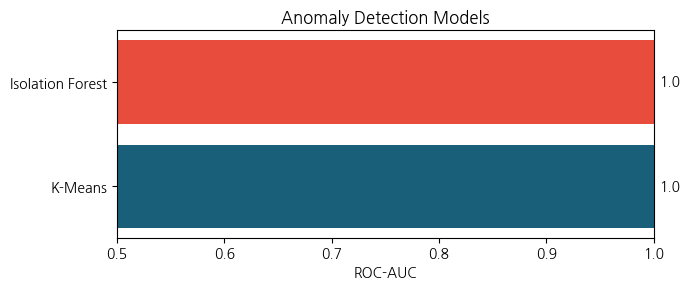

,model,AUC
0,K-Means,1.0
1,Isolation Forest,1.0


In [8]:
comparison = pd.DataFrame([
    {'model': 'K-Means',          'AUC': round(auc_km, 3)},
    {'model': 'Isolation Forest', 'AUC': round(auc_if, 3)},
])
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(comparison['model'], comparison['AUC'],
        color=['#1a5f7a', '#e74c3c'])
for i, v in enumerate(comparison['AUC']):
    ax.text(v + 0.005, i, f'{v}', va='center')
ax.set_xlim(0.5, 1.0)
ax.set_xlabel('ROC-AUC'); ax.set_title('Anomaly Detection Models')
plt.tight_layout(); plt.show()
comparison

---
## AutoEncoder 기반 이상 탐지 (딥러닝 확장)

신경망으로 **정상 트래픽을 압축·복원** 하도록 학습한 뒤 복원 오차가 큰 샘플을 이상으로 본다.
입력을 비선형으로 압축·복원하는 모델입니다. TensorFlow가 필요하며, 실행 환경의 설치 여부를 확인합니다.
- 목표: 정상(X_normal)으로 AutoEncoder 학습 → 복원 오차를 이상 점수로 → AUC 측정


In [9]:
# AutoEncoder 이상 탐지 — tensorflow 필요(Colab 기본 포함, 로컬은 pip install tensorflow)
try:
    from tensorflow import keras
    from tensorflow.keras import layers
    d = X_normal.shape[1]
    ae = keras.Sequential([
        layers.Input(shape=(d,)),
        layers.Dense(8, activation='relu'),
        layers.Dense(2, activation='relu'),      # bottleneck (입력보다 작게)
        layers.Dense(8, activation='relu'),
        layers.Dense(d, activation='linear'),
    ])
    ae.compile(optimizer='adam', loss='mse')
    ae.fit(X_normal, X_normal, epochs=20, batch_size=256, validation_split=0.1, verbose=0)

    mse_norm  = np.mean((X_valid_normal - ae.predict(X_valid_normal, verbose=0)) ** 2, axis=1)
    threshold = np.percentile(mse_norm, 95)
    scores_ae = np.mean((X - ae.predict(X, verbose=0)) ** 2, axis=1)
    auc_ae = roc_auc_score(y, scores_ae)
    print(f'AutoEncoder AUC = {auc_ae:.3f}  (threshold={threshold:.4f})')
except ImportError:
    print('tensorflow 미설치 — AutoEncoder 생략. Colab 또는 pip install tensorflow 후 실행')


I0000 00:00:1791242319.486679 3590142 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791242319.599140 3590142 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791242320.791540 3590142 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


AutoEncoder AUC = 1.000  (threshold=0.6107)


---
## Step 5. Isolation Forest — Threshold 튜닝

Best F1 = 1.000  @ threshold = 0.709
  Precision = 1.000, Recall = 1.000


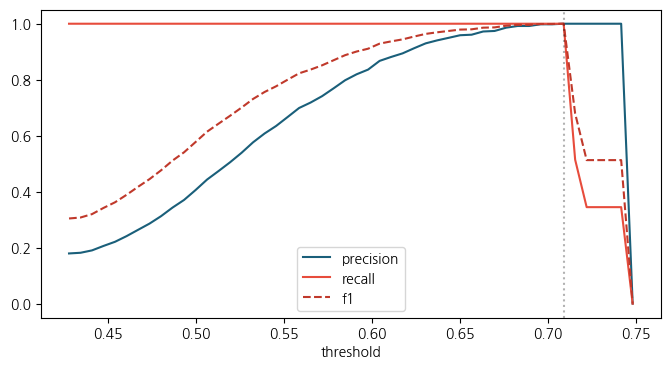

고정 임계값의 테스트 F1: 0.9980988593155894


In [10]:
valid_scores = -iforest.score_samples(X_valid)
thresholds = np.linspace(valid_scores.min(), valid_scores.max(), 50)
from sklearn.metrics import precision_score, recall_score, f1_score
rows = []
for t in thresholds:
    pred = (valid_scores > t).astype(int)
    rows.append({'threshold': t,
                 'precision': precision_score(y_valid, pred, zero_division=0),
                 'recall': recall_score(y_valid, pred, zero_division=0),
                 'f1': f1_score(y_valid, pred, zero_division=0)})
tune = pd.DataFrame(rows)
best = tune.loc[tune['f1'].idxmax()]
print(f'Best F1 = {best["f1"]:.3f}  @ threshold = {best["threshold"]:.3f}')
print(f'  Precision = {best["precision"]:.3f}, Recall = {best["recall"]:.3f}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tune['threshold'], tune['precision'], label='precision', color='#1a5f7a')
ax.plot(tune['threshold'], tune['recall'],    label='recall',    color='#e74c3c')
ax.plot(tune['threshold'], tune['f1'],        label='f1',        color='#c0392b', linestyle='--')
ax.axvline(best['threshold'], color='black', alpha=0.3, linestyle=':')
ax.set_xlabel('threshold'); ax.legend()
plt.show()
final_pred = (scores_if > float(best['threshold'])).astype(int)
print('고정 임계값의 테스트 F1:', f1_score(y, final_pred))

---
## 정리

- Isolation Forest·DBSCAN 등의 성능과 실행 시간은 데이터 분포·크기·설정에 따라 비교한다.
- DBSCAN 은 작은 데이터에 빠르지만 대용량은 어렵다.
- Threshold 튜닝으로 운영 시나리오(high recall vs high precision)에 맞춤.
- 다음 Part의 12~13장에서 로그·상관분석을 다루고, 14장에서 지도학습으로 넘어간다.